In [1]:
import sys
!{sys.executable} -m pip install --upgrade pip
!{sys.executable} -m pip install tensorflow


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix
from sklearn.preprocessing import LabelEncoder , StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense ,Dropout , Input

In [3]:
df = pd.read_csv('Churn_Modelling.csv')

In [4]:
df.head(20)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,6,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0
7,8,15656148,Obinna,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1
8,9,15792365,He,501,France,Male,44,4,142051.07,2,0,1,74940.50,0
9,10,15592389,H?,684,France,Male,27,2,134603.88,1,1,1,71725.73,0


In [5]:
df.info

<bound method DataFrame.info of       RowNumber  CustomerId    Surname  CreditScore Geography  Gender  Age  \
0             1    15634602   Hargrave          619    France  Female   42   
1             2    15647311       Hill          608     Spain  Female   41   
2             3    15619304       Onio          502    France  Female   42   
3             4    15701354       Boni          699    France  Female   39   
4             5    15737888   Mitchell          850     Spain  Female   43   
...         ...         ...        ...          ...       ...     ...  ...   
9995       9996    15606229   Obijiaku          771    France    Male   39   
9996       9997    15569892  Johnstone          516    France    Male   35   
9997       9998    15584532        Liu          709    France  Female   36   
9998       9999    15682355  Sabbatini          772   Germany    Male   42   
9999      10000    15628319     Walker          792    France  Female   28   

      Tenure    Balance  NumOfP

In [6]:
X = df.iloc[:,3:13]
y = df.iloc[:,13]

In [10]:
labelencoder_gender = LabelEncoder()
X['Gender'] = labelencoder_gender.fit_transform(X['Gender'])
X = pd.get_dummies(X,columns=['Geography'],drop_first=True)


In [11]:
X_train,X_test,y_train,y_test = train_test_split (X,y,test_size = 0.2 , random_state = 42)

In [12]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [13]:
model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(units=6 , activation ='relu'))
model.add(Dropout(0.3))
model.add(Dense(units=6 , activation = 'relu'))
model.add(Dense(units=1, activation = 'sigmoid'))

In [14]:
model.compile(optimizer = 'adam' , loss = 'binary_crossentropy',metrics=['accuracy'])

In [15]:
history = model.fit(X_train,y_train,epochs= 20 , batch_size =32 , validation_data = (X_test,y_test))

Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7421 - loss: 0.5950 - val_accuracy: 0.8045 - val_loss: 0.5134
Epoch 2/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7943 - loss: 0.5095 - val_accuracy: 0.8040 - val_loss: 0.4645
Epoch 3/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7985 - loss: 0.4767 - val_accuracy: 0.8080 - val_loss: 0.4391
Epoch 4/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8033 - loss: 0.4601 - val_accuracy: 0.8180 - val_loss: 0.4250
Epoch 5/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8077 - loss: 0.4561 - val_accuracy: 0.8195 - val_loss: 0.4174
Epoch 6/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8079 - loss: 0.4496 - val_accuracy: 0.8220 - val_loss: 0.4117
Epoch 7/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8104 - loss: 0.4440 - val_accuracy: 0.8255 - val_loss: 0.4077
Epoch 8/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8125 - loss: 0.4332 - val_accuracy: 0.

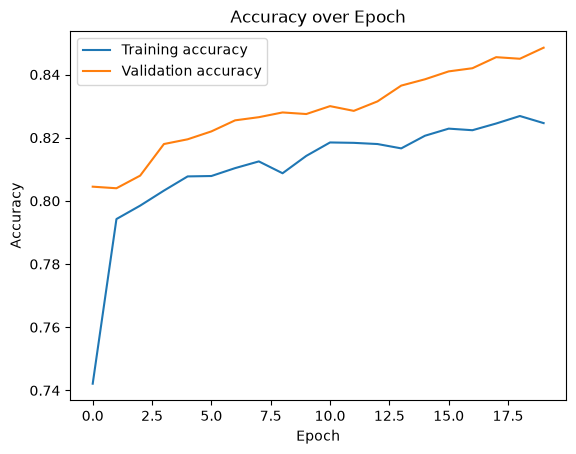

In [16]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'],label='Training accuracy')
plt.plot(history.history['val_accuracy'],label = 'Validation accuracy')
plt.title("Accuracy over Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [17]:
y_pred =(model.predict(X_test)>0.5).astype(int)

acc = accuracy_score(y_test,y_pred)
print("final accuracy:{:.2f}%".format(acc*100))
cm = confusion_matrix(y_test,y_pred)
print("confusion matrix:\n" ,cm)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
final accuracy:84.85%
confusion matrix:
 [[1583   24]
 [ 279  114]]
